# Semantic Similarity Data Vs Author

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/5d/40/e1e72872c6354b306daef1703549e8e83b4d43cfea356311bf722a043752/setuptools-83.0.0-py3-none-any.whl.metadata
    Using cached setuptools-83.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-83.0.0-py3-none-any.whl (1.0 MB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 83.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

In [2]:
import warnings

In [3]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [4]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [5]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [6]:
import tol_colors as tcls

In [7]:
import itertools as itlx
import json
from pathlib import Path
import re

In [8]:
from IPython.display import display, display_markdown

In [9]:
from pprint import pprint

In [10]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

In [11]:
pd.set_option('display.max_colwidth', None)

## Semantic Similarity

In [12]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [13]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [14]:
%config SqlMagic.autopandas = True
%load_ext sql
conn = ddb.connect()
%sql conn --alias duckdb

The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

In [15]:
%%sql
CREATE TABLE IF NOT EXISTS cons_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--cons_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,5934


In [16]:
%%sql
CREATE TABLE IF NOT EXISTS gt_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--gt_node_info_groups.csv';

-- NB: gt_dwc_t_author_nodes == gt_dwc_t_data_nodes
CREATE TABLE IF NOT EXISTS gt_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--gt_node_info_groups.csv';

-- NB: gt_eml_data_nodes == gt_eml_author_nodes
CREATE TABLE IF NOT EXISTS gt_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--gt_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,53666


In [17]:
%%sql
SELECT 
    (SELECT COUNT(1) FROM cons_dwc_t_data_nodes) AS dwc_t_data_node_count,
    (SELECT COUNT(1) FROM cons_dwc_t_author_nodes) AS dwc_t_author_node_count,
    (SELECT COUNT(1) FROM cons_eml_data_nodes) AS eml_data_node_count,
    (SELECT COUNT(1) FROM cons_eml_author_nodes) AS eml_author_node_count;

Running query in 'duckdb'

,dwc_t_data_node_count,dwc_t_author_node_count,eml_data_node_count,eml_author_node_count
0,8552,8562,6369,5934


In [18]:
%%sql
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes AS (
    SELECT  *,
            d.text as data_text, a.text as author_text,
            d.has_text as data_has_text, a.has_text as author_has_text,
            d.attributes as data_attributes, a.attributes as author_attributes,
            d.has_attributes as data_has_attributes, a.has_attributes as author_has_attributes
    FROM cons_dwc_t_data_nodes AS d
    JOIN cons_dwc_t_author_nodes AS a
        ON  a.path = d.path
        AND a.case_id = d.case_id
);

Running query in 'duckdb'

,Count
0,8212


In [19]:
%%sql
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes AS (
    SELECT  *,
            d.text as data_text, a.text as author_text,
            d.has_text as data_has_text, a.has_text as author_has_text,
            d.attributes as data_attributes, a.attributes as author_attributes,
            d.has_attributes as data_has_attributes, a.has_attributes as author_has_attributes
    FROM cons_eml_data_nodes AS d
    JOIN cons_eml_author_nodes AS a
        ON  a.path = d.path
        AND a.case_id = d.case_id
);

Running query in 'duckdb'

,Count
0,3876


#### Reporting Confusion Matrix

##### DwC-T

In [20]:
%%sql
SELECT COUNT(1), data_has_text, author_has_text
FROM shared_data_author_dwc_t_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),data_has_text,author_has_text
0,7954,False,False
1,258,True,True


In [21]:
%%sql
SELECT COUNT(1), data_has_attributes, author_has_attributes
FROM shared_data_author_dwc_t_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),data_has_attributes,author_has_attributes
0,516,False,False
1,7696,True,True


##### EML

In [22]:
%%sql
SELECT COUNT(1), data_has_text, author_has_text
FROM shared_data_author_eml_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),data_has_text,author_has_text
0,2226,False,False
1,30,False,True
2,21,True,False
3,1599,True,True


In [23]:
%%sql
SELECT COUNT(1), data_has_attributes, author_has_attributes
FROM shared_data_author_eml_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),data_has_attributes,author_has_attributes
0,3447,False,False
1,405,True,True
2,12,False,True
3,12,True,False


In [24]:
%%sql
SELECT c.path, c.tag, c.case_id, c.data_has_attributes, c.data_attributes, c.author_has_attributes, c.author_attributes
FROM shared_data_author_eml_nodes AS c
WHERE (data_has_attributes) AND (NOT author_has_attributes);

Running query in 'duckdb'

,path,tag,case_id,data_has_attributes,data_attributes,author_has_attributes,author_attributes
0,additionalMetadata,additionalMetadata,100,True,"{""id"": ""am-1""}",False,{}
1,additionalMetadata,additionalMetadata,125,True,"{""id"": ""am-1""}",False,{}
2,additionalMetadata,additionalMetadata,137,True,"{""id"": ""ext-1""}",False,{}
3,additionalMetadata,additionalMetadata,151,True,"{""id"": ""am-1""}",False,{}
4,dataset,dataset,169,True,"{""id"": ""203-37e24322-a8b9-3f3f-8686-4fa43445dc95""}",False,{}
5,additionalMetadata,additionalMetadata,21,True,"{""id"": ""customExtensions""}",False,{}
6,additionalMetadata,additionalMetadata,3,True,"{""id"": ""am-1""}",False,{}
7,additionalMetadata,additionalMetadata,45,True,"{""id"": ""amd-1""}",False,{}
8,additionalMetadata,additionalMetadata,5,True,"{""id"": ""am1""}",False,{}
9,additionalMetadata,additionalMetadata,6,True,"{""id"": ""am-1""}",False,{}


In [25]:
%%sql
SELECT c.path, c.tag, c.case_id, c.data_has_attributes, c.data_attributes, c.author_has_attributes, c.author_attributes
FROM shared_data_author_eml_nodes AS c
WHERE (NOT data_has_attributes) AND (author_has_attributes);

Running query in 'duckdb'

,path,tag,case_id,data_has_attributes,data_attributes,author_has_attributes,author_attributes
0,dataset,dataset,112,False,{},True,"{""id"": ""aedes_collection_dataset""}"
1,additionalMetadata,additionalMetadata,115,False,{},True,"{""id"": ""am-1""}"
2,dataset,dataset,144,False,{},True,"{""id"": ""dataset-1""}"
3,additionalMetadata,additionalMetadata,144,False,{},True,"{""id"": ""am-1""}"
4,additionalMetadata,additionalMetadata,163,False,{},True,"{""id"": ""am-001""}"
5,additionalMetadata,additionalMetadata,169,False,{},True,"{""id"": ""addl-1""}"
6,additionalMetadata,additionalMetadata,34,False,{},True,"{""id"": ""am-1""}"
7,additionalMetadata,additionalMetadata,50,False,{},True,"{""id"": ""am-1""}"
8,additionalMetadata,additionalMetadata,51,False,{},True,"{""id"": ""customExtensions""}"
9,additionalMetadata,additionalMetadata,63,False,{},True,"{""id"": ""am-1""}"


### Computing Similarities

In [26]:
if COS_SIMILARITY_READY:
    sentence_transformer_model = SentenceTransformer('all-MiniLM-L6-v2')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [27]:
def compute_cos_similarity(v1: str, v2:str) -> float | None:
    if v1 == v2:
        return 1.0
    if not v1 or not v2:
        return None

    emb1 = sentence_transformer_model.encode(v1).reshape(1,-1)
    emb2 = sentence_transformer_model.encode(v2).reshape(1,-1)

    return cosine_similarity(emb1, emb2)[0][0].item()

In [28]:
compute_cos_similarity("{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}", "{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}")

1.0

In [29]:
conn.create_function("cos_sim", compute_cos_similarity)

In [30]:
%%time
shared_data_author_dwc_t_nodes__sim_text = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_text AS (
SELECT
    case_id, path,
    data_text, author_text,
    cos_sim(data_text, author_text) AS cos_sim_text,
FROM shared_data_author_dwc_t_nodes
WHERE data_has_text AND author_has_text
);
SELECT * FROM shared_data_author_dwc_t_nodes__sim_text;
""").to_df()


shared_data_author_dwc_t_nodes__sim_attributes = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes AS (
SELECT
    case_id, path,
    data_attributes, author_attributes,
    cos_sim(data_attributes, author_attributes) AS cos_sim_attributes,
FROM shared_data_author_dwc_t_nodes
WHERE data_has_attributes AND author_has_attributes
);
SELECT * FROM shared_data_author_dwc_t_nodes__sim_attributes;
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 10.7 s, sys: 1.74 s, total: 12.5 s
Wall time: 17.9 s


In [31]:
%%time
shared_data_author_eml_nodes__sim_text = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes__sim_text AS (
SELECT
    case_id, path,
    data_text, author_text,
    cos_sim(data_text, author_text) AS cos_sim_text,
FROM shared_data_author_eml_nodes
WHERE data_has_text AND author_has_text
);
SELECT * FROM shared_data_author_eml_nodes__sim_text;
""").to_df()


shared_data_author_eml_nodes__sim_attributes = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes__sim_attributes AS (
SELECT
    case_id, path,
    data_attributes, author_attributes,
    cos_sim(data_attributes, author_attributes) AS cos_sim_attributes,
FROM shared_data_author_eml_nodes
WHERE data_has_attributes AND author_has_attributes
);
SELECT * FROM shared_data_author_eml_nodes__sim_attributes;
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 21.9 s, sys: 5.85 s, total: 27.8 s
Wall time: 20.3 s


### Basic insights

#### DwC-T

In [32]:
%%sql
SELECT d.path, AVG(cos_sim_text), COUNT(1)   
FROM shared_data_author_dwc_t_nodes__sim_text AS d
GROUP BY 1
ORDER BY 2 DESC, 3 DESC;

Running query in 'duckdb'

,path,avg(cos_sim_text),count(1)
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.972965,169
1,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.934475,59
2,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.782424,14
3,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.760269,14
4,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.524897,2


In [33]:
%%sql
SELECT d.path, AVG(cos_sim_attributes), COUNT(1)   
FROM shared_data_author_dwc_t_nodes__sim_attributes AS d
GROUP BY 1
ORDER BY 2 DESC, 3 DESC;

Running query in 'duckdb'

,path,avg(cos_sim_attributes),count(1)
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[28],1.000000,95
1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[58],1.000000,13
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[64],1.000000,11
3,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[60],1.000000,11
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[62],1.000000,11
...,...,...,...
308,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[44],0.705396,1
309,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[35],0.694667,1
310,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[32],0.682424,1
311,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field,0.655420,1


<Axes: ylabel='Frequency'>

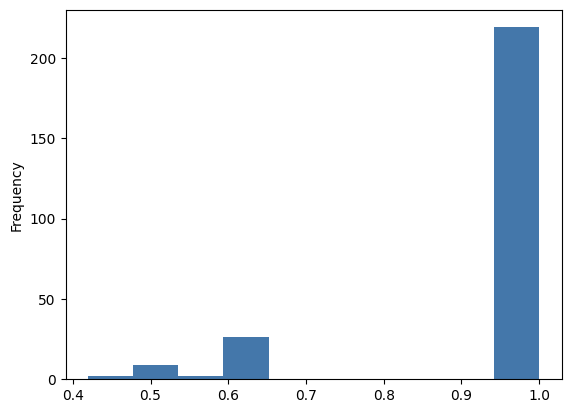

In [34]:
shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"].plot.hist()

<Axes: ylabel='Frequency'>

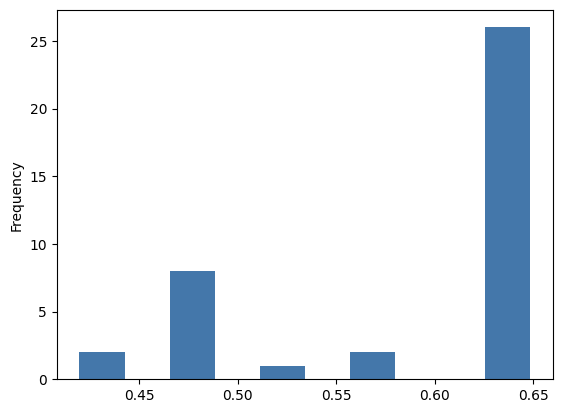

In [35]:
shared_data_author_dwc_t_nodes__sim_text[
    shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"] < 1
]["cos_sim_text"].plot.hist()

<Axes: ylabel='Frequency'>

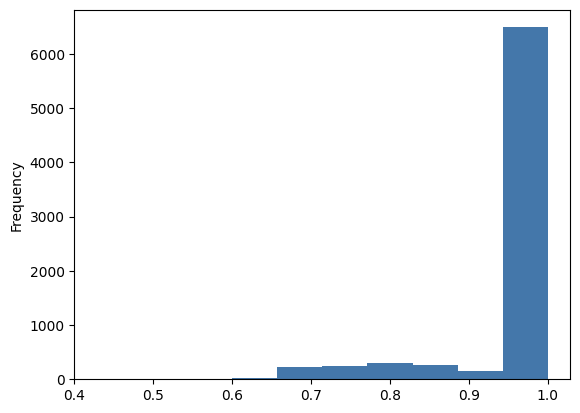

In [36]:
shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"].plot.hist()

<Axes: ylabel='Frequency'>

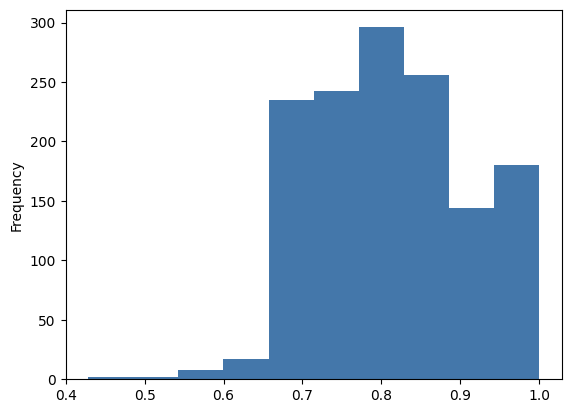

In [37]:
shared_data_author_dwc_t_nodes__sim_attributes[
    shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"] < 1
]["cos_sim_attributes"].plot.hist()

#### EML

<Axes: ylabel='Frequency'>

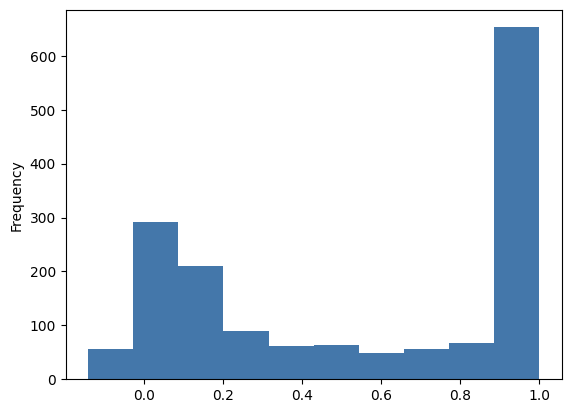

In [38]:
shared_data_author_eml_nodes__sim_text["cos_sim_text"].plot.hist()

<Axes: ylabel='Frequency'>

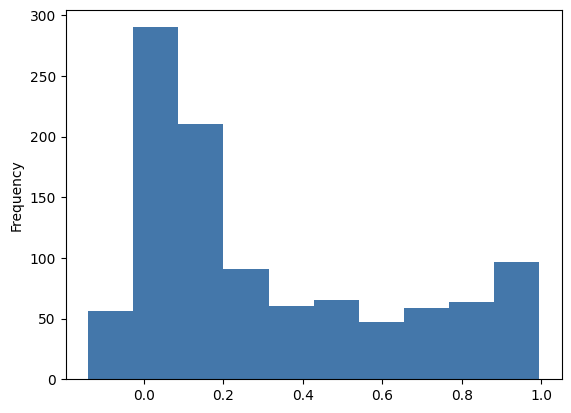

In [39]:
shared_data_author_eml_nodes__sim_text[
    shared_data_author_eml_nodes__sim_text["cos_sim_text"] < 1
]["cos_sim_text"].plot.hist()

<Axes: ylabel='Frequency'>

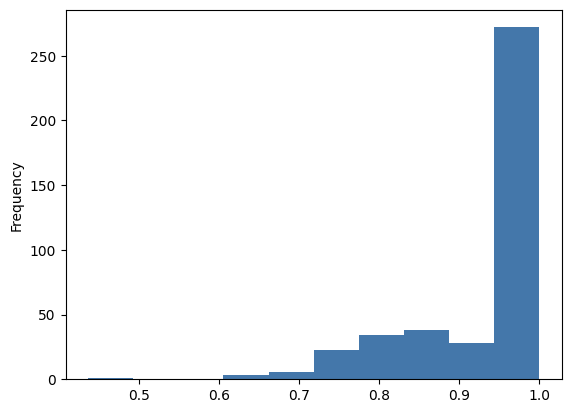

In [40]:
shared_data_author_eml_nodes__sim_attributes["cos_sim_attributes"].plot.hist()

<Axes: ylabel='Frequency'>

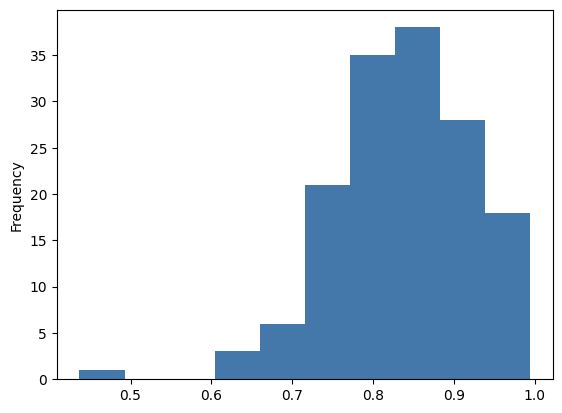

In [41]:
shared_data_author_eml_nodes__sim_attributes[
    shared_data_author_eml_nodes__sim_attributes["cos_sim_attributes"] < 1
]["cos_sim_attributes"].plot.hist()

### Inspect Prepping

In [42]:
%%sql shared_data_author_dwc_t_nodes__sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM shared_data_author_dwc_t_nodes__sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_author_dwc_t_nodes__sim_text__path_inspect;

Running query in 'duckdb'

In [43]:
%%sql shared_data_author_dwc_t_nodes__sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM shared_data_author_dwc_t_nodes__sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_author_dwc_t_nodes__sim_attributes__path_inspect;

Running query in 'duckdb'

In [44]:
%%sql shared_data_author_eml_nodes__sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes__sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM shared_data_author_eml_nodes__sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_author_eml_nodes__sim_text__path_inspect;

Running query in 'duckdb'

In [45]:
%%sql shared_data_author_eml_nodes__sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes__sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM shared_data_author_eml_nodes__sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_author_eml_nodes__sim_attributes__path_inspect;

Running query in 'duckdb'

In [46]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect = (
    shared_data_author_dwc_t_nodes__sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
shared_data_author_dwc_t_nodes__sim_attributes__path_inspect = (
    shared_data_author_dwc_t_nodes__sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
shared_data_author_eml_nodes__sim_text__path_inspect = (
    shared_data_author_eml_nodes__sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
shared_data_author_eml_nodes__sim_attributes__path_inspect = (
    shared_data_author_eml_nodes__sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)

In [47]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,14,14,0.252923,0.782424,1.000000,0.419757,1.000000,0.492633,1.000000
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,59,59,0.136876,0.934475,1.000000,0.648550,1.000000,1.000000,1.000000
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,169,169,0.093651,0.972965,1.000000,0.648550,1.000000,1.000000,1.000000
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,2,2,0.041696,0.524897,0.566593,0.483202,0.524897,0.504050,0.545745
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,14,14,0.246918,0.760269,1.000000,0.419757,0.824275,0.483202,1.000000


In [48]:
shared_data_author_dwc_t_nodes__sim_attributes__path_inspect

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
22286206021010697,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[84],2,2,0.052487,0.947513,1.0,0.895027,0.947513,0.921270,0.973757
54879317211468838,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[85],2,2,0.047679,0.952321,1.0,0.904642,0.952321,0.928482,0.976161
95853930020399204,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[125],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
111850653873045131,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[130],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
255409801921677082,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[116],2,2,0.082750,0.917250,1.0,0.834499,0.917250,0.875874,0.958625
...,...,...,...,...,...,...,...,...,...,...
18123143049830882349,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[94],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
18205186968821406156,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[138],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
18249724521440334599,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[90],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000


In [49]:
print(f"{shared_data_author_dwc_t_nodes__sim_text__path_inspect.shape=}")
print(f"{shared_data_author_dwc_t_nodes__sim_attributes__path_inspect.shape=}")

print(f"{shared_data_author_eml_nodes__sim_text__path_inspect.shape=}")
print(f"{shared_data_author_eml_nodes__sim_attributes__path_inspect.shape=}")

shared_data_author_dwc_t_nodes__sim_text__path_inspect.shape=(5, 10)
shared_data_author_dwc_t_nodes__sim_attributes__path_inspect.shape=(313, 10)
shared_data_author_eml_nodes__sim_text__path_inspect.shape=(38, 10)
shared_data_author_eml_nodes__sim_attributes__path_inspect.shape=(7, 10)


### Inspections DwC-T

#### Setting the stage

In [101]:
%%sql 
-- shared ancestor paths Data X Author X? GT
SELECT COUNT(1), sd.data_has_text, sd.author_has_text, gt.has_text
FROM shared_data_author_dwc_t_nodes AS sd
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON sd.path = gt.path
    AND sd.case_id = gt.case_id
GROUP BY 2,3,4

Running query in 'duckdb'

,count(1),data_has_text,author_has_text,has_text
0,7724,False,False,False
1,258,True,True,True
2,230,False,False,<NA>


In [126]:
%%sql triple_equivalence_breakdown <<
-- counts of similarity triples: DxA, DxGT, AxGT
SELECT sd.data_text = sd.author_text, sd.data_text = gt.text, sd.author_text = gt.text, COUNT(1) AS cnt
FROM shared_data_author_dwc_t_nodes AS sd
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON sd.path = gt.path
    AND sd.case_id = gt.case_id
WHERE sd.data_has_text AND sd.author_has_text AND gt.has_text
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

In [127]:
triple_equivalence_breakdown

,(sd.data_text = sd.author_text),"(sd.data_text = gt.""text"")","(sd.author_text = gt.""text"")",cnt
0,False,False,False,7
1,False,False,True,10
2,False,True,False,22
3,True,False,False,44
4,True,True,True,175


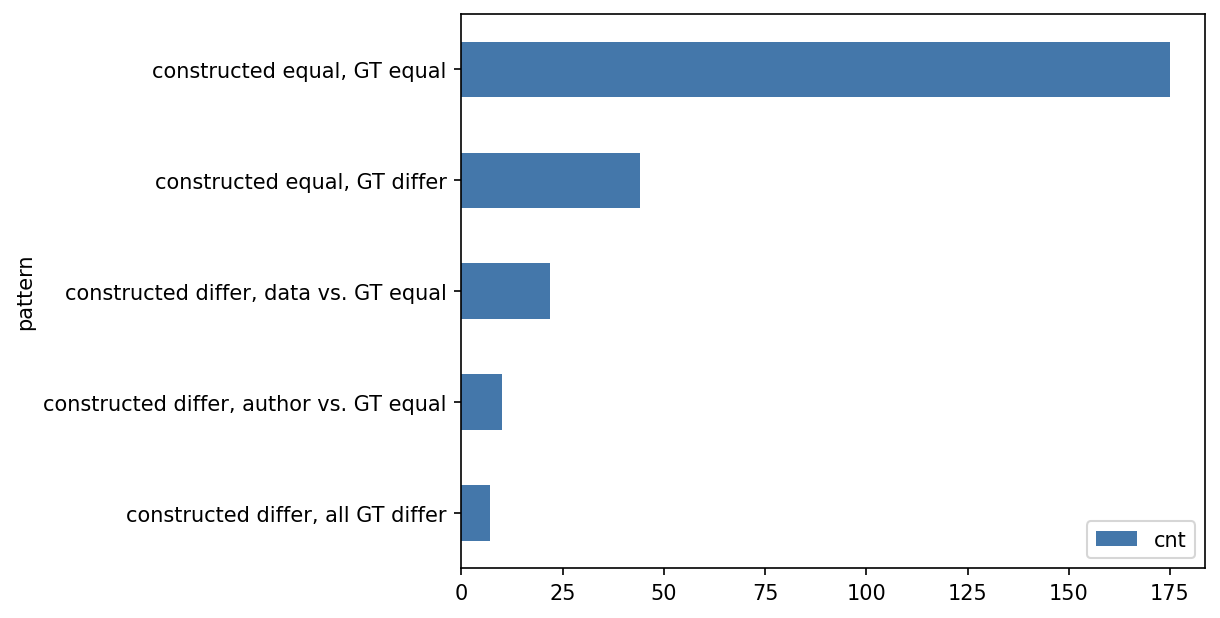

In [138]:
# triple_equivalence_breakdown["pattern"] = [
#     "(sd.data_text != sd.author_text) & (sd.data_text != gt.'text') & (sd.author_text != gt.'text')",
#     "(sd.data_text != sd.author_text) & (sd.data_text != gt.'text') & (sd.author_text = gt.'text')",
#     "(sd.data_text != sd.author_text) & (sd.data_text = gt.'text') & (sd.author_text != gt.'text')",
#     "(sd.data_text = sd.author_text) & (sd.data_text != gt.'text') & (sd.author_text != gt.'text')",
#     "(sd.data_text = sd.author_text) & (sd.data_text = gt.'text') & (sd.author_text = gt.'text')",
# ]
triple_equivalence_breakdown["pattern"] = [
    "constructed differ, all GT differ",
    "constructed differ, author vs. GT equal",
    "constructed differ, data vs. GT equal",
    "constructed equal, GT differ",
    "constructed equal, GT equal",
]
fig, ax = plt.subplots(dpi=150)
triple_equivalence_breakdown.plot.barh(x="pattern", y="cnt", ax=ax)
plt.show()

In [185]:
%%sql 
-- similarity scores: DxA, DxGT, AxGT
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__with_gt AS (
-- CREATE OR REPLACE TABLE shared_data_author_dwc_t_nodes__with_gt AS (
    SELECT *, gt.text as gt_text, cos_sim(sd.data_text, gt.text) AS cos_sim_data_gt, cos_sim(sd.author_text, gt.text) AS cos_sim_author_gt
    FROM shared_data_author_dwc_t_nodes AS sd
    LEFT JOIN gt_dwc_t_data_nodes AS gt
        ON sd.path = gt.path
        AND sd.case_id = gt.case_id
    WHERE sd.data_has_text AND sd.author_has_text AND gt.has_text
);
SELECT * FROM shared_data_author_dwc_t_nodes__with_gt;

Running query in 'duckdb'

,column00,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,...,is_leaf_2,attributes_2,attributes_count_2,has_attributes_2,text_2,has_text_2,path_2,gt_text,cos_sim_data_gt,cos_sim_author_gt
0,2085,135,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
1,2111,136,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
2,2142,137,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,event.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,0.64855,0.64855
3,2177,137,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,event.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,0.64855,0.64855
4,2196,138,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
253,1759,131,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
254,1811,132,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,event.txt,...,True,{},0,False,event.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,1.00000,1.00000
255,1836,132,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
256,1858,133,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000


In [151]:
%%sql path_count_to_avg_medians <<
-- We observe that more files in the dataset cause poorer performance
WITH sim_per_case_dwc_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        stddev_pop(cos_sim_data_gt) as ds_std_pop_d_gt,
        stddev_pop(cos_sim_author_gt) as ds_std_pop_a_gt,
        AVG(cos_sim_data_gt) as ds_mean_d_gt,
        AVG(cos_sim_author_gt) as ds_mean_a_gt,
        MAX(cos_sim_data_gt) as ds_max_d_gt,
        MAX(cos_sim_author_gt) as ds_max_a_gt,
        MIN(cos_sim_data_gt) as ds_min_d_gt,
        MIN(cos_sim_author_gt) as ds_min_a_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_med_cont_d_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p25_cont_d_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p75_cont_d_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_med_cont_a_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p25_cont_a_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p75_cont_a_gt,
    FROM shared_data_author_dwc_t_nodes__with_gt as c
    GROUP BY c.case_id
)
SELECT path_count, COUNT(1) AS cnt, AVG(ds_med_cont_d_gt) AS avg_median_d_gt, AVG(ds_med_cont_a_gt) AS avg_median_a_gt
FROM sim_per_case_dwc_text
GROUP BY 1
ORDER BY 1

Running query in 'duckdb'

In [152]:
path_count_to_avg_medians

,path_count,cnt,avg_median_d_gt,avg_median_a_gt
0,1,96,1.000000,1.000000
1,2,59,0.878509,0.860639
2,3,12,0.678204,0.664549
3,4,2,0.683988,0.579919


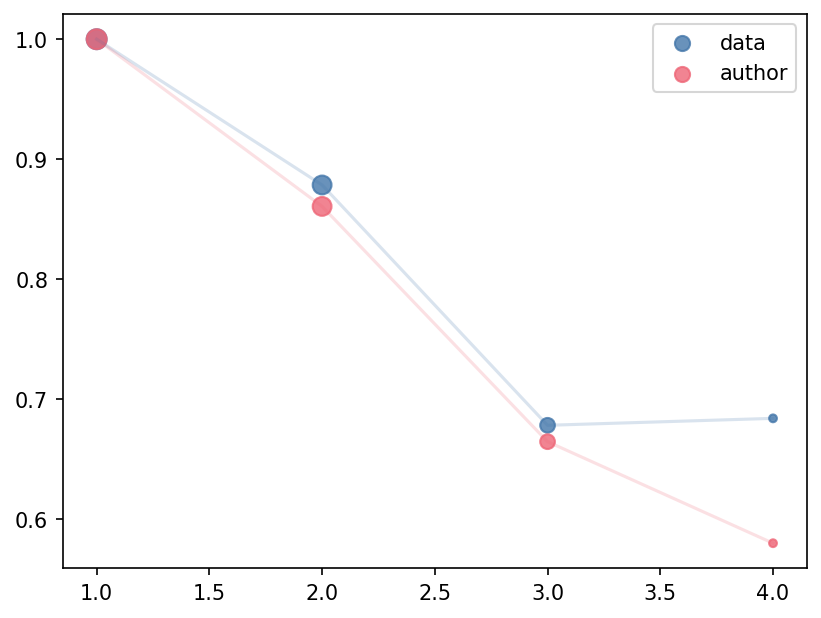

In [160]:
fig,ax = plt.subplots(dpi=150)
ax.plot(
    path_count_to_avg_medians["path_count"], 
    path_count_to_avg_medians["avg_median_d_gt"],
    alpha=0.2
)
ax.scatter(
    x=path_count_to_avg_medians["path_count"], 
    y=path_count_to_avg_medians["avg_median_d_gt"], 
    sizes=np.log(path_count_to_avg_medians["cnt"]) * 20,
    alpha=0.8,
    label="data"
)
ax.plot(
    path_count_to_avg_medians["path_count"], 
    path_count_to_avg_medians["avg_median_a_gt"],
    alpha=0.2
)
ax.scatter(
    x=path_count_to_avg_medians["path_count"], 
    y=path_count_to_avg_medians["avg_median_a_gt"], 
    sizes=np.log(path_count_to_avg_medians["cnt"]) * 20,
    alpha=0.8,
    label="author"
)
ax.legend()
plt.show()

In [162]:
%%sql
-- regression testing correlation between case size and similarity
WITH sim_per_case_dwc_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        stddev_pop(cos_sim_data_gt) as ds_std_pop_d_gt,
        stddev_pop(cos_sim_author_gt) as ds_std_pop_a_gt,
        AVG(cos_sim_data_gt) as ds_mean_d_gt,
        AVG(cos_sim_author_gt) as ds_mean_a_gt,
        MAX(cos_sim_data_gt) as ds_max_d_gt,
        MAX(cos_sim_author_gt) as ds_max_a_gt,
        MIN(cos_sim_data_gt) as ds_min_d_gt,
        MIN(cos_sim_author_gt) as ds_min_a_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_med_cont_d_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p25_cont_d_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p75_cont_d_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_med_cont_a_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p25_cont_a_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p75_cont_a_gt,
    FROM shared_data_author_dwc_t_nodes__with_gt as c
    GROUP BY c.case_id
)
SELECT regr_r2(ds_med_cont_d_gt, path_count), regr_r2(ds_med_cont_d_gt, path_count)
FROM sim_per_case_dwc_text

Running query in 'duckdb'

,"regr_r2(ds_med_cont_d_gt, path_count)","regr_r2(ds_med_cont_d_gt, path_count)_1"
0,0.361623,0.361623


#### Text

In [163]:
print(shared_data_author_dwc_t_nodes__sim_text.shape)
print(shared_data_author_dwc_t_nodes__sim_text[shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"] == 1].shape)
print(shared_data_author_dwc_t_nodes__sim_text[shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"] < 1].shape)

(258, 5)
(219, 5)
(39, 5)


In [164]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect.describe()

,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,51.600000,51.600000,0.154413,0.795006,0.913319,0.523963,0.869835,0.695977,0.909149
std,69.146945,69.146945,0.093496,0.177091,0.193825,0.116644,0.207296,0.277632,0.203149
min,2.000000,2.000000,0.041696,0.524897,0.566593,0.419757,0.524897,0.483202,0.545745
25%,14.000000,14.000000,0.093651,0.760269,1.000000,0.419757,0.824275,0.492633,1.000000
50%,14.000000,14.000000,0.136876,0.782424,1.000000,0.483202,1.000000,0.504050,1.000000
75%,59.000000,59.000000,0.246918,0.934475,1.000000,0.648550,1.000000,1.000000,1.000000
max,169.000000,169.000000,0.252923,0.972965,1.000000,0.648550,1.000000,1.000000,1.000000


In [165]:
shared_data_author_dwc_t_nodes__sim_text[shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"] < 1].describe()

,case_id,cos_sim_text
count,39.000000,39.000000
mean,96.102564,0.595198
std,54.402397,0.080307
min,5.000000,0.419757
25%,43.000000,0.502064
50%,103.000000,0.648550
75%,141.000000,0.648550
max,174.000000,0.648550


In [166]:
%%sql
-- regression testing correlation between case size and similarity
WITH sim_per_case_dwc_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        COUNT(cos_sim_text) as ds_count,
        stddev_pop(cos_sim_text) as ds_std_pop,
        AVG(cos_sim_text) as ds_mean,
        MAX(cos_sim_text) as ds_max,
        MIN(cos_sim_text) as ds_min,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
    FROM shared_data_author_dwc_t_nodes__sim_text as c
    GROUP BY c.case_id
)
SELECT regr_r2(ds_med_cont, path_count)
FROM sim_per_case_dwc_text

Running query in 'duckdb'

,"regr_r2(ds_med_cont, path_count)"
0,0.284998


In [167]:
%%sql
WITH sim_per_case_dwc_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        COUNT(cos_sim_text) as ds_count,
        stddev_pop(cos_sim_text) as ds_std_pop,
        AVG(cos_sim_text) as ds_mean,
        MAX(cos_sim_text) as ds_max,
        MIN(cos_sim_text) as ds_min,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
    FROM shared_data_author_dwc_t_nodes__sim_text as c
    GROUP BY c.case_id
)
SELECT path_count, COUNT(1), AVG(ds_med_cont)
FROM sim_per_case_dwc_text
GROUP BY 1
ORDER BY 1

Running query in 'duckdb'

,path_count,count(1),avg(ds_med_cont)
0,1,96,1.000000
1,2,59,0.934475
2,3,12,0.763626
3,4,2,0.642680


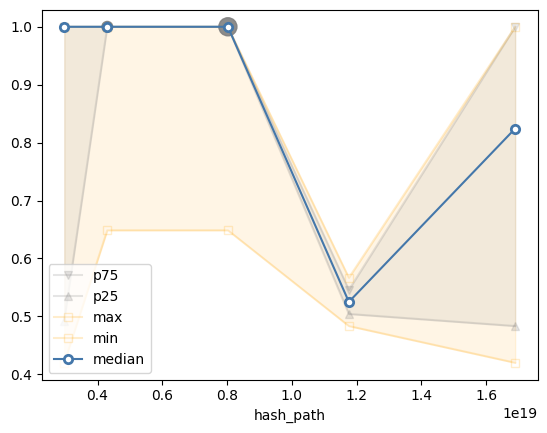

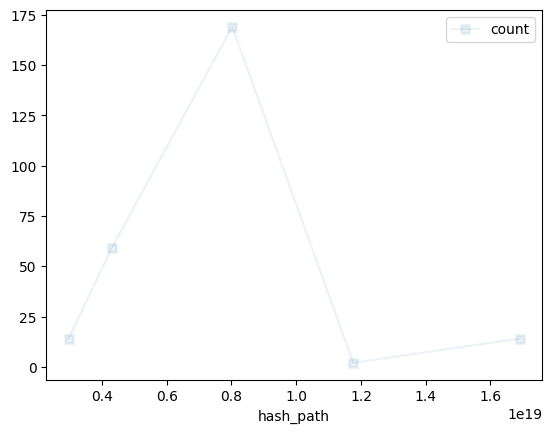

In [168]:
df = shared_data_author_dwc_t_nodes__sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont'], sizes=(df['ds_count']), color="gray", alpha=0.9)
plt.legend(loc="lower left")
plt.show()
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

#### Attributes

In [267]:
%%sql
-- attributes constructed by data
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS (
SELECT d.path, d.case_id, d.cos_sim_attributes, dja.key, dja.value
FROM 
    shared_data_author_dwc_t_nodes__sim_attributes AS d,
    json_each(d.data_attributes) AS dja
);

-- attributes constructed by author
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS (
SELECT d.path, d.case_id, d.cos_sim_attributes, aja.key, aja.value
FROM 
    shared_data_author_dwc_t_nodes__sim_attributes AS d,
    json_each(d.author_attributes) AS aja
);

-- attributes from ground truth
CREATE 
    OR REPLACE 
    TABLE 
    -- IF NOT EXISTS 
    gt_dwc_t_data_nodes__attributes__unpacked AS (
SELECT d.path, d.attributes, d.case_id, aja.key, aja.value
FROM 
    gt_dwc_t_data_nodes AS d,
    json_each(d.attributes) AS aja
);

Running query in 'duckdb'

,Count
0,17245


In [245]:
%%sql 
SELECT * FROM gt_dwc_t_data_nodes__attributes__unpacked;

Running query in 'duckdb'

,path,case_id,key,value
0,.,0,metadata,"""eml.xml"""
1,{http://rs.tdwg.org/dwc/text/}core,0,rowType,"""http://rs.tdwg.org/dwc/terms/Event"""
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}id,0,index,"""0"""
3,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],0,term,"""http://rs.tdwg.org/dwc/terms/eventID"""
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],0,term,"""http://rs.tdwg.org/dwc/terms/eventDate"""
...,...,...,...,...
17240,{http://rs.tdwg.org/dwc/text/}extension[2],170,encoding,"""UTF-8"""
17241,{http://rs.tdwg.org/dwc/text/}core,171,encoding,"""UTF-8"""
17242,{http://rs.tdwg.org/dwc/text/}core,172,encoding,"""UTF-8"""
17243,{http://rs.tdwg.org/dwc/text/}extension,172,encoding,"""UTF-8"""


In [169]:
col = shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"]
mask = (col < 1) & ~np.isclose(col, 1.0)

print(shared_data_author_dwc_t_nodes__sim_attributes.shape)
print(shared_data_author_dwc_t_nodes__sim_attributes[shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"] == 1].shape)
print(shared_data_author_dwc_t_nodes__sim_attributes[mask].shape)

(7696, 5)
(6313, 5)
(1381, 5)


In [170]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect.describe()

,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,51.600000,51.600000,0.154413,0.795006,0.913319,0.523963,0.869835,0.695977,0.909149
std,69.146945,69.146945,0.093496,0.177091,0.193825,0.116644,0.207296,0.277632,0.203149
min,2.000000,2.000000,0.041696,0.524897,0.566593,0.419757,0.524897,0.483202,0.545745
25%,14.000000,14.000000,0.093651,0.760269,1.000000,0.419757,0.824275,0.492633,1.000000
50%,14.000000,14.000000,0.136876,0.782424,1.000000,0.483202,1.000000,0.504050,1.000000
75%,59.000000,59.000000,0.246918,0.934475,1.000000,0.648550,1.000000,1.000000,1.000000
max,169.000000,169.000000,0.252923,0.972965,1.000000,0.648550,1.000000,1.000000,1.000000


In [173]:
# workaround for float64
col = shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"]
mask_lt_1 = (col < 1) & ~np.isclose(col, 1.0)
mask_eq_1 = (col == 1) | np.isclose(col, 1.0)

display(shared_data_author_dwc_t_nodes__sim_attributes[mask_lt_1].describe())
display(shared_data_author_dwc_t_nodes__sim_attributes[mask_eq_1].describe())

,case_id,cos_sim_attributes
count,1381.000000,1381.000000
mean,93.476466,0.810837
std,53.275769,0.099347
min,2.000000,0.428500
25%,43.000000,0.732835
50%,96.000000,0.808477
75%,137.000000,0.880683
max,178.000000,0.999148


,case_id,cos_sim_attributes
count,6315.000000,6.315000e+03
mean,88.937451,1.000000e+00
std,50.436430,2.121645e-09
min,0.000000,9.999999e-01
25%,47.000000,1.000000e+00
50%,92.000000,1.000000e+00
75%,132.000000,1.000000e+00
max,178.000000,1.000000e+00


In [178]:
%%sql
-- overview of mixed up attributes: data x author
SELECT aja.key, COUNT(1) AS cnt 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1
ORDER BY cnt
;

Running query in 'duckdb'

,key,cnt
0,delimitedBy,2
1,rowType,18
2,fieldsTerminatedBy,21
3,metadata,92
4,index,271
5,term,479


In [181]:
%%sql
-- overview of mixed up attributes: data x author
SELECT aja.path, aja.key, COUNT(1) AS cnt 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1,2
ORDER BY cnt
;

Running query in 'duckdb'

,path,key,cnt
0,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[38],term,1
1,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[34],term,1
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[116],term,1
3,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[154],term,1
4,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[45],term,1
...,...,...,...
246,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,16
247,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,18
248,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,21
249,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,30


In [186]:
%%sql
-- inferred equivalently
SELECT *
FROM shared_data_author_dwc_t_nodes__with_gt
WHERE gt_text = author_text AND gt_text = data_text;

Running query in 'duckdb'

,column00,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,...,is_leaf_2,attributes_2,attributes_count_2,has_attributes_2,text_2,has_text_2,path_2,gt_text,cos_sim_data_gt,cos_sim_author_gt
0,2085,135,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
1,2111,136,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
2,2196,138,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
3,2229,139,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
4,2260,14,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170,1759,131,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
171,1811,132,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,event.txt,...,True,{},0,False,event.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,1.0,1.0
172,1836,132,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
173,1858,133,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0


In [203]:
%%sql
-- inferred equivalently, reconstruct matchin path subsequences
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__with_gt__inferred_equivalently AS (
    SELECT split(d.path, '/{')[1] AS file_subpath, d.case_id
    FROM shared_data_author_dwc_t_nodes__with_gt AS d
    WHERE gt_text = author_text AND gt_text = data_text  
);
SELECT * FROM shared_data_author_dwc_t_nodes__with_gt__equivalently_inferred;

Running query in 'duckdb'

,file_subpath,case_id
0,{http://rs.tdwg.org/dwc/text/}core,135
1,{http://rs.tdwg.org/dwc/text/}core,136
2,{http://rs.tdwg.org/dwc/text/}core,138
3,{http://rs.tdwg.org/dwc/text/}core,139
4,{http://rs.tdwg.org/dwc/text/}core,14
...,...,...
170,{http://rs.tdwg.org/dwc/text/}core,131
171,{http://rs.tdwg.org/dwc/text/}core,132
172,{http://rs.tdwg.org/dwc/text/}extension,132
173,{http://rs.tdwg.org/dwc/text/}core,133


In [268]:
%%sql
-- inferred identical yet different, reconstruct matchin path subsequences
CREATE 
    -- OR REPLACE 
    TABLE 
    IF NOT EXISTS 
    shared_data_author_dwc_t_nodes__with_gt__identical_yet_different AS (
    SELECT split(d.path, '/{')[1]  AS file_subpath, d.case_id
    FROM shared_data_author_dwc_t_nodes__with_gt AS d
    WHERE data_text = author_text AND author_text <> gt_text AND data_text <> gt_text
);
SELECT * FROM shared_data_author_dwc_t_nodes__with_gt__identical_yet_different;

Running query in 'duckdb'

,file_subpath,case_id
0,{http://rs.tdwg.org/dwc/text/}core,137
1,{http://rs.tdwg.org/dwc/text/}extension,137
2,{http://rs.tdwg.org/dwc/text/}core,152
3,{http://rs.tdwg.org/dwc/text/}core,154
4,{http://rs.tdwg.org/dwc/text/}extension,154
5,{http://rs.tdwg.org/dwc/text/}core,155
6,{http://rs.tdwg.org/dwc/text/}extension,155
7,{http://rs.tdwg.org/dwc/text/}core,159
8,{http://rs.tdwg.org/dwc/text/}core,16
9,{http://rs.tdwg.org/dwc/text/}extension,16


In [229]:
%%sql 
(SELECT DISTINCT case_id FROM shared_data_author_dwc_t_nodes__with_gt__identical_yet_different)
EXCEPT 
(SELECT DISTINCT case_id FROM shared_data_author_dwc_t_nodes__with_gt__equivalently_inferred)
;

Running query in 'duckdb'

,case_id
0,2
1,60
2,63
3,101
4,62
5,137
6,159
7,42
8,112
9,154


In [269]:
%%sql
-- check path patterns for attributes
SELECT split(aja.path, '/{')[1], aja.case_id, COUNT(1) AS cnt_attributes 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1,2
ORDER BY case_id, cnt_attributes

Running query in 'duckdb'

,"split(aja.path, '/{')[1]",case_id,cnt_attributes
0,.,2,1
1,{http://rs.tdwg.org/dwc/text/}extension,2,7
2,{http://rs.tdwg.org/dwc/text/}core,2,21
3,.,3,1
4,{http://rs.tdwg.org/dwc/text/}core,6,3
...,...,...,...
197,.,172,1
198,{http://rs.tdwg.org/dwc/text/}extension,172,5
199,.,175,1
200,.,177,1


In [270]:
%%sql
-- check path patterns for attributes, distinct paths
SELECT split(aja.path, '/{')[1], COUNT(1) AS cnt_attributes 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1
ORDER BY cnt_attributes

Running query in 'duckdb'

,"split(aja.path, '/{')[1]",cnt_attributes
0,{http://rs.tdwg.org/dwc/text/}extension[1],33
1,{http://rs.tdwg.org/dwc/text/}extension[2],71
2,.,92
3,{http://rs.tdwg.org/dwc/text/}core,270
4,{http://rs.tdwg.org/dwc/text/}extension,417


In [283]:
%%sql
-- equivalently inferred triples
CREATE 
    OR REPLACE
    TABLE 
    -- IF NOT EXISTS 
    equivalently_inferred_triples_attributes AS (
    SELECT *, dja.value as data_value, aja.value as author_value, gtja.key AS gt_key, gtja.value AS gt_value
    FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
    JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
        ON  aja.path = dja.path
        AND aja.case_id = dja.case_id
        AND aja.key = dja.key
    LEFT JOIN gt_dwc_t_data_nodes__attributes__unpacked as gtja
        ON gtja.path = aja.path
        AND gtja.case_id = aja.case_id
        AND gtja.key = aja.key
    LEFT JOIN shared_data_author_dwc_t_nodes__with_gt__inferred_equivalently AS ies
        ON (ies.file_subpath = split(aja.path, '/{')[1]  AND ies.case_id = aja.case_id) 
    WHERE aja.value <> dja.value
        -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
        -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
        AND aja.case_id NOT IN (
            SELECT DISTINCT d.case_id
            FROM shared_data_author_dwc_t_nodes__sim_text AS d
            WHERE d.data_text <> d.author_text
        )
        AND ((file_subpath IS NOT Null) OR aja.path = '.')
);
SELECT split(ats.path, '/{')[1], COUNT(1) AS cnt_attributes 
FROM equivalently_inferred_triples_attributes AS ats
GROUP BY 1
ORDER BY cnt_attributes

Running query in 'duckdb'

,"split(ats.path, '/{')[1]",cnt_attributes
0,{http://rs.tdwg.org/dwc/text/}extension[1],25
1,{http://rs.tdwg.org/dwc/text/}extension[2],28
2,.,92
3,{http://rs.tdwg.org/dwc/text/}core,196
4,{http://rs.tdwg.org/dwc/text/}extension,263


In [284]:
%%sql
-- identical yet different triples
CREATE 
    OR REPLACE
    TABLE 
    -- IF NOT EXISTS 
    identical_yet_different_triples_attributes AS (
    SELECT *, dja.value as data_value, aja.value as author_value, gtja.key AS gt_key, gtja.value AS gt_value
    FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
    JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
        ON  aja.path = dja.path
        AND aja.case_id = dja.case_id
        AND aja.key = dja.key
    LEFT JOIN gt_dwc_t_data_nodes__attributes__unpacked as gtja
        ON gtja.path = aja.path
        AND gtja.case_id = aja.case_id
        AND gtja.key = aja.key
    JOIN shared_data_author_dwc_t_nodes__with_gt__identical_yet_different AS ies
        ON (ies.file_subpath = split(aja.path, '/{')[1]  AND ies.case_id = aja.case_id) 
    WHERE aja.value <> dja.value
        -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
        -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
        AND aja.case_id NOT IN (
            SELECT DISTINCT d.case_id
            FROM shared_data_author_dwc_t_nodes__sim_text AS d
            WHERE d.data_text <> d.author_text
        )
        -- AND ((file_subpath IS NOT Null) OR aja.path = '.')
);
SELECT split(ats.path, '/{')[1], COUNT(1) AS cnt_attributes 
FROM identical_yet_different_triples_attributes AS ats
GROUP BY 1
ORDER BY cnt_attributes

Running query in 'duckdb'

,"split(ats.path, '/{')[1]",cnt_attributes
0,{http://rs.tdwg.org/dwc/text/}extension[1],8
1,{http://rs.tdwg.org/dwc/text/}extension[2],43
2,{http://rs.tdwg.org/dwc/text/}core,74
3,{http://rs.tdwg.org/dwc/text/}extension,154


In [273]:
%%sql
-- equivalently inferred hierarchies: difference per attribute value
SELECT ats.key, COUNT(1) AS cnt 
FROM equivalently_inferred_triples_attributes AS ats
GROUP BY 1
ORDER BY 2;

Running query in 'duckdb'

,key,cnt
0,delimitedBy,2
1,rowType,14
2,fieldsTerminatedBy,15
3,metadata,92
4,index,133
5,term,348


In [286]:
%%sql
-- identical yet different triples: difference per attribute value
SELECT ats.key, COUNT(1) AS cnt 
FROM identical_yet_different_triples_attributes AS ats
GROUP BY 1
ORDER BY 2;

Running query in 'duckdb'

,key,cnt
0,rowType,4
1,fieldsTerminatedBy,6
2,term,131
3,index,138


#### Per attribute pattern

In [285]:
%%sql
-- inspect I/E:K1
-- ==> massi adds the `delimitedBy` attribute to the gt metadata
-- ==> by manual check, massi is closer to the data than the GT metadata (the `|` is indeed used)
-- ==> it differs in surrounding the delimiter with whitespace
SELECT * 
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'delimitedBy'
;

Running query in 'duckdb'

,path,case_id,cos_sim_attributes,key,value,path_1,case_id_1,cos_sim_attributes_1,key_1,value_1,...,attributes,case_id_2,key_2,value_2,file_subpath,case_id_3,data_value,author_value,gt_key,gt_value
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[11],59,1.0,delimitedBy,"""|""",{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[11],59,1.0,delimitedBy,""" | """,...,None,<NA>,None,None,{http://rs.tdwg.org/dwc/text/}core,59,"""|""",""" | """,None,None
1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[25],59,1.0,delimitedBy,"""|""",{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[25],59,1.0,delimitedBy,""" | """,...,None,<NA>,None,None,{http://rs.tdwg.org/dwc/text/}core,59,"""|""",""" | """,None,None


In [289]:
%%sql
-- inspect I/E:K2
SELECT data_value, author_value, gt_value
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'rowType'
;

Running query in 'duckdb'

,data_value,author_value,gt_value
0,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence"""
1,"""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.gbif.org/terms/1.0/Multimedia"""
2,"""http://rs.tdwg.org/dwc/terms/Media""","""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.gbif.org/terms/1.0/Multimedia"""
3,"""http://rs.tdwg.org/dwc/terms/MaterialSample""","""http://rs.gbif.org/dwc/terms/DNADerivedData""","""http://rs.gbif.org/terms/1.0/DNADerivedData"""
4,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence"""
5,"""http://rs.tdwg.org/dwc/terms/MaterialCitation""","""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.gbif.org/terms/1.0/Multimedia"""
6,"""http://rs.tdwg.org/dwc/terms/MaterialSample""","""http://rs.tdwg.org/dwc/terms/DnaDerivedData""","""http://rs.gbif.org/terms/1.0/DNADerivedData"""
7,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence"""
8,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence"""
9,"""http://rs.gbif.org/terms/1.0/DNADerivedData""","""http://rs.tdwg.org/dwc/terms/MaterialSample""","""http://rs.gbif.org/terms/1.0/DNADerivedData"""


In [ ]:
%%sql
-- inspect I/E:K2
SELECT data_value, author_value, gt_value
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'rowType'
;

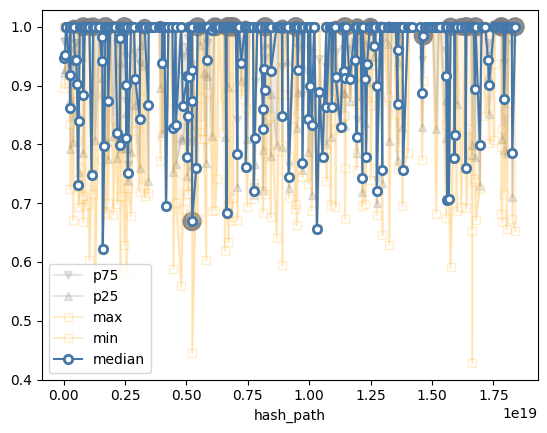

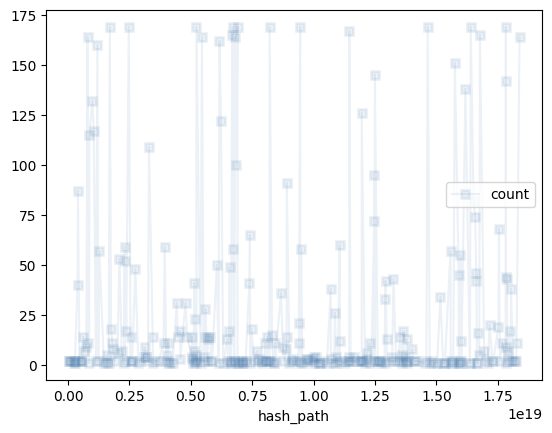

In [172]:
df = shared_data_author_dwc_t_nodes__sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont'], sizes=(df['ds_count']), color="gray", alpha=0.9)
plt.legend(loc="lower left")
plt.show()
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

In [60]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect.nsmallest(10, columns=["ds_med_cont"])

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,2,2,0.041696,0.524897,0.566593,0.483202,0.524897,0.504050,0.545745
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,14,14,0.246918,0.760269,1.000000,0.419757,0.824275,0.483202,1.000000
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,14,14,0.252923,0.782424,1.000000,0.419757,1.000000,0.492633,1.000000
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,59,59,0.136876,0.934475,1.000000,0.648550,1.000000,1.000000,1.000000
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,169,169,0.093651,0.972965,1.000000,0.648550,1.000000,1.000000,1.000000


In [61]:
shared_data_author_dwc_t_nodes__sim_attributes__path_inspect.nsmallest(10, columns=["ds_med_cont"])

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
1589770393185182661,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}field[8],1,1,0.000000,0.621950,0.621950,0.621950,0.621950,0.621950,0.621950
10312634465911785389,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field,1,1,0.000000,0.655420,0.655420,0.655420,0.655420,0.655420,0.655420
5227831486160219788,.,169,169,0.163558,0.796019,1.000000,0.445228,0.668868,0.668868,1.000000
6633044823982244110,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[32],1,1,0.000000,0.682424,0.682424,0.682424,0.682424,0.682424,0.682424
4166473755248203668,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[35],1,1,0.000000,0.694667,0.694667,0.694667,0.694667,0.694667,0.694667
15616206012361833326,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[44],1,1,0.000000,0.705396,0.705396,0.705396,0.705396,0.705396,0.705396
15687683872871601652,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[34],1,1,0.000000,0.707864,0.707864,0.707864,0.707864,0.707864,0.707864
12746096366820304841,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}field[4],2,2,0.040303,0.719857,0.760159,0.679554,0.719857,0.699706,0.740008
7741584035691069954,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}field[5],2,2,0.013297,0.721095,0.734392,0.707798,0.721095,0.714446,0.727743


### Inspections EML

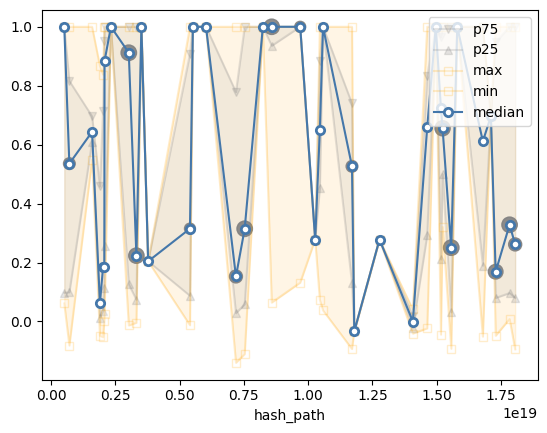

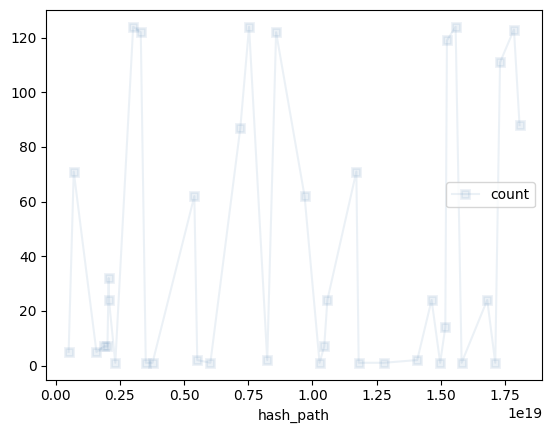

In [62]:
df = shared_data_author_eml_nodes__sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont'], sizes=(df['ds_count']), color="gray", alpha=0.9)
plt.legend(loc="upper right")
plt.show()
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

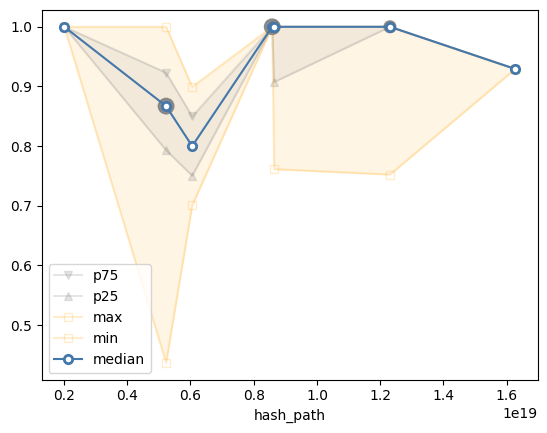

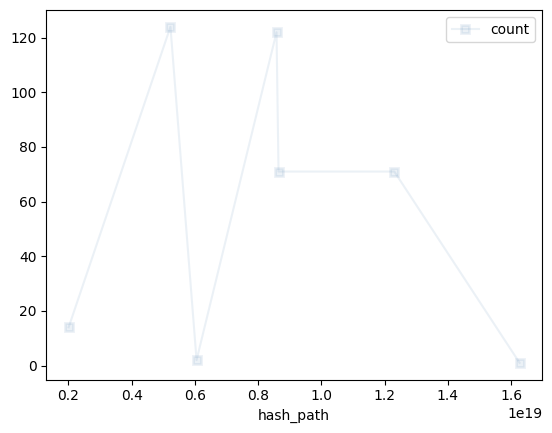

In [63]:
df = shared_data_author_eml_nodes__sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont'], sizes=(df['ds_count']), color="gray", alpha=0.9)
plt.legend(loc="lower left")
plt.show()
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

In [64]:
shared_data_author_eml_nodes__sim_text__path_inspect.nsmallest(10, columns=["ds_med_cont"])

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
11797055351399041090,dataset/project/abstract/para,1,1,0.000000,-0.033338,-0.033338,-0.033338,-0.033338,-0.033338,-0.033338
14075849902049915488,dataset/project/studyAreaDescription/descriptor[3]/descriptorValue,2,2,0.040895,-0.000308,0.040587,-0.041203,-0.000308,-0.020755,0.020140
1897832894039290149,dataset/methods/methodStep[1]/description/para,7,7,0.356680,0.260279,0.866275,-0.048814,0.061705,0.013307,0.458088
7191309023196111392,dataset/methods/methodStep/description/para,87,87,0.402133,0.363468,1.000000,-0.140305,0.152646,0.027980,0.778725
17299146993214317173,dataset/methods/qualityControl/description/para,111,111,0.402947,0.386541,1.000000,-0.048544,0.168804,0.079673,0.947337
2019908457384792944,dataset/methods/methodStep[2]/description/para,7,7,0.360038,0.352727,0.837763,-0.053558,0.184812,0.035197,0.714839
2068281925885941007,additionalMetadata/metadata,32,32,0.380010,0.381493,1.000000,0.000302,0.185584,0.114107,0.953267
3774517024663899732,additionalMetadata/metadata/customMetadata/provenanceNote,1,1,0.000000,0.204093,0.204093,0.204093,0.204093,0.204093,0.204093
3316978768188658723,dataset/maintenance/maintenanceUpdateFrequency,122,122,0.436868,0.483997,1.000000,-0.004451,0.223308,0.073879,1.000000


In [65]:
shared_data_author_eml_nodes__sim_attributes__path_inspect.nsmallest(10, columns=["ds_med_cont"])

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
6053456406947778033,dataset/project/studyAreaDescription/descriptor[3],2,2,0.099219,0.799988,0.899207,0.700769,0.799988,0.750378,0.849597
5227831486160219788,.,124,124,0.100370,0.854348,1.000000,0.436732,0.867016,0.793100,0.923025
16270227087059927836,additionalMetadata,1,1,0.000000,0.929274,0.929274,0.929274,0.929274,0.929274,0.929274
2007448060941507434,dataset/project/studyAreaDescription/descriptor,14,14,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
8583186042160731940,dataset/creator/userId,122,122,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
8646466898135044654,dataset/project/studyAreaDescription/descriptor[2],71,71,0.078912,0.950725,1.000000,0.761374,1.000000,0.907518,1.000000
12309451528792936862,dataset/project/studyAreaDescription/descriptor[1],71,71,0.075603,0.968155,1.000000,0.752345,1.000000,1.000000,1.000000


### Exploration

#### DwC-T

In [66]:
%%sql
SELECT d.path, case_id, cos_sim_text, data_text, author_text
FROM shared_data_author_dwc_t_nodes__sim_text AS d
WHERE cos_sim_text < 1
ORDER BY cos_sim_text ASC, case_id ASC
;

Running query in 'duckdb'

,path,case_id,cos_sim_text,data_text,author_text
0,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,130,0.419757,measurementorfact.txt,occurrence.txt
1,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,130,0.419757,occurrence.txt,measurementorfact.txt
2,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,0.480255,event.txt,measurementorfacts.txt
3,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,152,0.480255,event.txt,measurementorfacts.txt
4,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,152,0.480255,measurementorfacts.txt,event.txt
5,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,0.483202,extendedmeasurementorfact.txt,event.txt
6,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,116,0.483202,event.txt,extendedmeasurementorfact.txt
7,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,116,0.483202,extendedmeasurementorfact.txt,event.txt
8,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,159,0.483202,event.txt,extendedmeasurementorfact.txt
9,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,159,0.483202,extendedmeasurementorfact.txt,event.txt


In [67]:
%%sql
SELECT d.path, case_id, cos_sim_attributes, data_attributes, author_attributes
FROM shared_data_author_dwc_t_nodes__sim_attributes AS d
WHERE cos_sim_attributes < 1
ORDER BY cos_sim_attributes ASC, case_id ASC
;

Running query in 'duckdb'

,path,case_id,cos_sim_attributes,data_attributes,author_attributes
0,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[8],92,0.428500,"{""index"": ""8"", ""term"": ""Classification classify-sklearn (QIIME feature-classifier classify-sklearn) on a classifier that was trained using the naive Bayes classifier algorithm (QIIME feature-classifier fit-classifier-naive-bayes)""}","{""index"": ""8"", ""term"": ""not-derived-009""}"
1,.,46,0.445228,"{""metadata"": ""Ascorhynchus hippos Turpaeva, 1994""}","{""metadata"": ""omit or leave empty""}"
2,.,104,0.532437,"{""metadata"": ""meta.xml""}","{""metadata"": ""not-derived-001` is unavailable. The interview confirmed that no separate metadata file or URI/path such as `meta.xml`, `eml.xml`, or `metadata.xml` was identified in the provided material.'}}}""}"
3,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[4],92,0.541082,"{""index"": ""4"", ""term"": ""http://example.org/molecular-assay/target-gene/ITS""}","{""index"": ""4"", ""term"": ""not-derived-005""}"
4,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[17],103,0.558338,"{""index"": ""17"", ""term"": ""http://rs.tdwg.org/dwc/terms/scientificNameAuthorship""}","{""index"": ""16"", ""term"": ""http://rs.tdwg.org/dwc/terms/decimalLatitude""}"
...,...,...,...,...,...
1377,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[12],65,0.994138,"{""index"": ""12"", ""term"": ""http://rs.tdwg.org/dwc/terms/locality""}","{""index"": ""11"", ""term"": ""http://rs.tdwg.org/dwc/terms/locality""}"
1378,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[10],65,0.994559,"{""index"": ""10"", ""term"": ""http://rs.tdwg.org/dwc/terms/countryCode""}","{""index"": ""9"", ""term"": ""http://rs.tdwg.org/dwc/terms/countryCode""}"
1379,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[11],65,0.995531,"{""index"": ""11"", ""term"": ""http://rs.tdwg.org/dwc/terms/municipality""}","{""index"": ""10"", ""term"": ""http://rs.tdwg.org/dwc/terms/municipality""}"
1380,{http://rs.tdwg.org/dwc/text/}core,151,0.999148,"{""rowType"": ""http://rs.tdwg.org/dwc/terms/Occurrence"", ""fieldsTerminatedBy"": ""&#x9;"", ""fieldsEnclosedBy"": ""&quot;"", ""ignoreHeaderLines"": ""1"", ""encoding"": ""UTF-8""}","{""rowType"": ""http://rs.tdwg.org/dwc/terms/Occurrence"", ""fieldsTerminatedBy"": ""&#9;"", ""fieldsEnclosedBy"": ""&quot;"", ""ignoreHeaderLines"": ""1"", ""encoding"": ""UTF-8""}"


In [68]:
%%sql
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS (
SELECT d.path, d.case_id, d.cos_sim_attributes, dja.key, dja.value
FROM 
    shared_data_author_dwc_t_nodes__sim_attributes AS d,
    json_each(d.data_attributes) AS dja
);
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS (
SELECT d.path, d.case_id, d.cos_sim_attributes, aja.key, aja.value
FROM 
    shared_data_author_dwc_t_nodes__sim_attributes AS d,
    json_each(d.author_attributes) AS aja
);

Running query in 'duckdb'

,Count
0,15634


In [69]:
%%sql
SELECT d.path, d.case_id, d.data_text, d.author_text, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_text AS d
WHERE d.data_text <> d.author_text
GROUP BY 1,2,3,4
ORDER BY d.case_id, cnt

Running query in 'duckdb'

,path,case_id,data_text,author_text,cnt
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,5,event.txt,occurrence.txt,1
1,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,5,occurrence.txt,event.txt,1
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,18,event.txt,occurrence.txt,1
3,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,18,occurrence.txt,event.txt,1
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,25,event.txt,occurrence.txt,1
5,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,25,occurrence.txt,event.txt,1
6,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,measurementorfacts.txt,extendedmeasurementorfact.txt,1
7,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,extendedmeasurementorfact.txt,event.txt,1
8,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,event.txt,measurementorfacts.txt,1
9,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,43,occurrence.txt,event.txt,1


In [70]:
%%sql
SELECT d.path, d.case_id, d.data_text, d.author_text, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_text AS d
WHERE d.data_text <> d.author_text
GROUP BY 1,2,3,4
ORDER BY d.case_id, cnt

Running query in 'duckdb'

,path,case_id,data_text,author_text,cnt
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,5,event.txt,occurrence.txt,1
1,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,5,occurrence.txt,event.txt,1
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,18,event.txt,occurrence.txt,1
3,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,18,occurrence.txt,event.txt,1
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,25,event.txt,occurrence.txt,1
5,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,25,occurrence.txt,event.txt,1
6,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,extendedmeasurementorfact.txt,event.txt,1
7,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,event.txt,measurementorfacts.txt,1
8,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,measurementorfacts.txt,extendedmeasurementorfact.txt,1
9,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,43,event.txt,occurrence.txt,1


In [71]:
%%sql dwc_t_cases_with_text_value_mismatch <<
SELECT d.case_id, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_text AS d
WHERE d.data_text <> d.author_text
GROUP BY 1,
ORDER BY d.case_id, cnt

Running query in 'duckdb'

In [72]:
%%sql
SELECT 
    -- d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    -- gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    -- d.data_text = d.author_text as data_equal_author,
    COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
-- GROUP BY 1,2,3
-- ORDER BY 4

Running query in 'duckdb'

,cnt
0,258


In [73]:
%%sql
SELECT 
    -- d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE d.data_text = d.author_text
    AND d.data_text = gt.text
    AND d.author_text = gt.text
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

,data_ok,author_ok,data_equal_author,cnt
0,True,True,True,175


In [74]:
%%sql
SELECT d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, gt_text = d.data_text as data_ok, gt_text = d.author_text as author_ok
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text
ORDER BY d.case_id

Running query in 'duckdb'

,case_id,path,data_text,author_text,gt_text,data_ok,author_ok
0,0,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,event.txt,occurrence.txt,False,False
1,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,event.txt,False,False
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,event.txt,False,False
3,2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,event.txt,occurrence.txt,False,False
4,3,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,event.txt,False,False
...,...,...,...,...,...,...,...
78,170,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,multimedia.txt,multimedia.txt,permit.txt,False,False
79,173,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True
80,173,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True
81,174,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,event.txt,True,False


In [75]:
%%sql
SELECT 
    -- d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

,data_ok,author_ok,data_equal_author,cnt
0,False,False,False,7
1,False,True,False,10
2,True,False,False,22
3,False,False,True,44


In [76]:
%%sql
SELECT 
    d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    -- COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE 
    (d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text)
AND data_ok
;

Running query in 'duckdb'

,case_id,path,data_text,author_text,gt_text,data_ok,author_ok,data_equal_author
0,103,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,event.txt,True,False,False
1,103,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,occurrence.txt,True,False,False
2,116,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,extendedmeasurementorfact.txt,event.txt,extendedmeasurementorfact.txt,True,False,False
3,118,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,event.txt,True,False,False
4,118,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,occurrence.txt,True,False,False
5,124,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,dna_data.csv,media.csv,dna_data.csv,True,False,False
6,152,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,measurementorfacts.txt,event.txt,measurementorfacts.txt,True,False,False
7,159,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,extendedmeasurementorfact.txt,event.txt,extendedmeasurementorfact.txt,True,False,False
8,164,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,event.txt,True,False,False
9,164,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,occurrence.txt,True,False,False


In [77]:
%%sql
SELECT 
    d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    -- COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE 
    (d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text)
AND author_ok
;

Running query in 'duckdb'

,case_id,path,data_text,author_text,gt_text,data_ok,author_ok,data_equal_author
0,130,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,measurementorfact.txt,occurrence.txt,occurrence.txt,False,True,False
1,130,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,measurementorfact.txt,measurementorfact.txt,False,True,False
2,173,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True,False
3,173,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True,False
4,43,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True,False
5,43,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True,False
6,45,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True,False
7,45,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True,False
8,86,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True,False
9,86,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True,False


In [78]:
%%sql
SELECT 
    d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    -- COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE 
    (d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text)
AND NOT data_equal_author
AND NOT data_ok
AND NOT author_ok
;

Running query in 'duckdb'

,case_id,path,data_text,author_text,gt_text,data_ok,author_ok,data_equal_author
0,116,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,extendedmeasurementorfact.txt,occurrence.txt,False,False,False
1,124,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,media.csv,dna_data.csv,measurements.csv,False,False,False
2,152,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,measurementorfacts.txt,occurrence.txt,False,False,False
3,159,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,extendedmeasurementorfact.txt,occurrence.txt,False,False,False
4,42,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,measurementorfacts.txt,extendedmeasurementorfact.txt,False,False,False
5,42,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,extendedmeasurementorfact.txt,event.txt,occurrence.txt,False,False,False
6,78,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,measurementorfacts.txt,False,False,False


In [79]:
%%sql
SELECT aja.path, aja.case_id, aja.key, aja.value AS author_value, dja.value AS data_value, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
GROUP BY 1,2,3,4,5 
ORDER BY aja.case_id, cnt
;

Running query in 'duckdb'

,path,case_id,key,author_value,data_value,cnt
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}id,2,index,"""0""","""10""",1
1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[9],2,term,"""http://rs.tdwg.org/dwc/terms/dynamicProperties""","""http://rs.tdwg.org/dwc/terms/basisOfRecord""",1
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],2,term,"""http://rs.tdwg.org/dwc/terms/institutionID""","""http://rs.tdwg.org/dwc/terms/license""",1
3,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[4],2,index,"""4""","""3""",1
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[5],2,index,"""5""","""4""",1
...,...,...,...,...,...,...
1693,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[13],174,term,"""http://rs.tdwg.org/dwc/terms/countryCode""","""http://rs.tdwg.org/dwc/terms/scientificName""",1
1694,.,175,metadata,"""not-derived-001""","""meta.xml""",1
1695,.,177,metadata,"""not-derived-001""","""meta.xml""",1
1696,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],178,term,"""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified""",1


In [80]:
%%sql dwc_t_cases_with_attribute_value_mismatch <<
SELECT aja.case_id, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
GROUP BY 1
ORDER BY aja.case_id, cnt
;

Running query in 'duckdb'

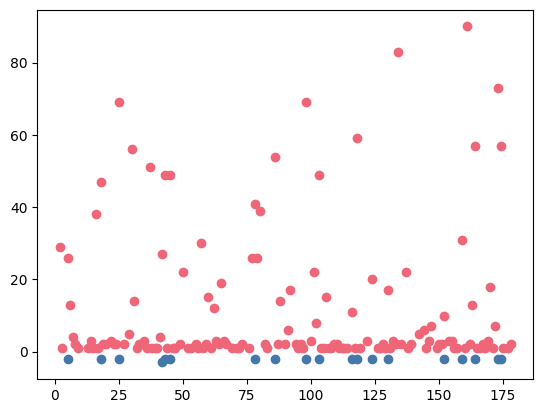

In [81]:
plt.scatter(
    dwc_t_cases_with_text_value_mismatch["case_id"],
    dwc_t_cases_with_text_value_mismatch["cnt"] * (-1)
)
plt.scatter(
    dwc_t_cases_with_attribute_value_mismatch["case_id"], 
    dwc_t_cases_with_attribute_value_mismatch["cnt"]
)

<Axes: ylabel='Frequency'>

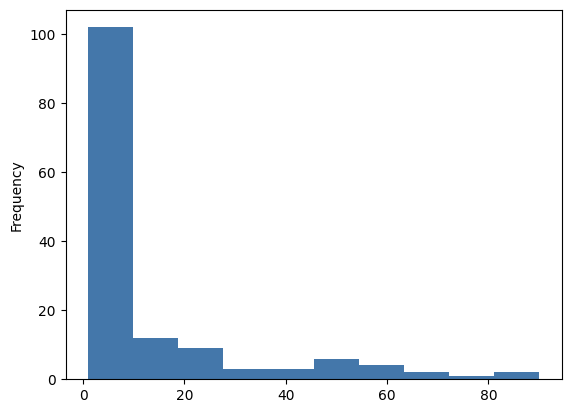

In [82]:
dwc_t_cases_with_attribute_value_mismatch["cnt"].plot.hist()

In [83]:
dwc_t_cases_with_attribute_value_mismatch.nlargest(15, columns=["cnt"])

,case_id,cnt
127,161,90
107,134,83
139,173,73
18,25,69
77,98,69
95,118,59
130,164,57
140,174,57
21,30,56
67,86,54


In [84]:
set(dwc_t_cases_with_text_value_mismatch["case_id"].tolist())

{5,
 18,
 25,
 42,
 43,
 45,
 78,
 86,
 98,
 103,
 116,
 118,
 124,
 130,
 152,
 159,
 164,
 173,
 174}

In [85]:
set(dwc_t_cases_with_attribute_value_mismatch.nlargest(15, columns=["cnt"])["case_id"].tolist())

{18, 25, 30, 37, 43, 45, 86, 98, 103, 118, 134, 161, 164, 173, 174}

In [86]:
(
    set.difference(
        set(dwc_t_cases_with_text_value_mismatch["case_id"].tolist()),
        set(dwc_t_cases_with_attribute_value_mismatch.nlargest(50, columns=["cnt"])["case_id"].tolist()),
    ),
    
    set.difference(
        set(dwc_t_cases_with_attribute_value_mismatch.nlargest(50, columns=["cnt"])["case_id"].tolist()),
        set(dwc_t_cases_with_text_value_mismatch["case_id"].tolist()),
    )
)

(set(),
 {2,
  6,
  7,
  16,
  29,
  30,
  31,
  37,
  50,
  57,
  60,
  62,
  65,
  77,
  79,
  80,
  88,
  91,
  92,
  101,
  102,
  106,
  134,
  137,
  142,
  144,
  147,
  161,
  163,
  170,
  172})

In [87]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value as author_value, dja.value as data_value
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP')
ORDER BY aja.case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,2,.,metadata,"""not-derived-001""","""meta.xml"""
1,3,.,metadata,"""not-derived-001""","""meta.xml"""
2,8,.,metadata,"""not-derived-001""","""meta.xml"""
3,9,.,metadata,"""not-derived-001""","""meta.xml"""
4,13,.,metadata,"""not-derived-001""","""meta.xml"""
...,...,...,...,...,...
110,171,.,metadata,"""not-derived-001""","""meta.xml"""
111,173,.,metadata,"""not-derived-001""","""meta.xml"""
112,174,.,metadata,"""not-derived-001""","""GAP_001"""
113,175,.,metadata,"""not-derived-001""","""meta.xml"""


In [88]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value as author_value, dja.value as data_value
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP')
ORDER BY aja.case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,19,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/type""","""not-derived-002"""
1,19,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/type""","""not-derived-003"""
2,42,.,metadata,"""meta.xml""","""not-derived-001"""
3,56,.,metadata,"""meta.xml""","""not-derived-001"""
4,57,.,metadata,"""meta.xml""","""not-derived-001"""
5,64,.,metadata,"""meta.xml""","""not-derived-001"""
6,92,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[3],term,"""not-derived-004""","""not-derived-003"""
7,92,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[7],term,"""not-derived-008""","""not-derived-007"""
8,92,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[10],term,"""not-derived-011""","""not-derived-010"""
9,106,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/permitType""","""not-derived-002"""


In [89]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value as author_value, dja.value as data_value
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
ORDER BY aja.case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/datasetName""","""http://rs.tdwg.org/dwc/terms/type"""
1,2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/eventID""","""http://rs.tdwg.org/dwc/terms/datasetName"""
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],index,"""1""","""0"""
3,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],index,"""2""","""1"""
4,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],index,"""3""","""2"""
...,...,...,...,...,...
1560,174,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6],index,"""6""","""5"""
1561,174,{http://rs.tdwg.org/dwc/text/}core,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event"""
1562,174,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence"""
1563,178,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified"""


In [90]:
%%sql
SELECT aja.key, COUNT(1) AS cnt 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1
ORDER BY aja.key, cnt
;

Running query in 'duckdb'

,key,cnt
0,delimitedBy,2
1,fieldsTerminatedBy,21
2,index,271
3,metadata,6
4,rowType,17
5,term,460


In [91]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/language""","""http://purl.org/dc/terms/language"""
1,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license"""
2,101,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}id,index,"""0""","""10"""
3,101,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/type""","""http://rs.tdwg.org/dwc/terms/id"""
4,101,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://rs.tdwg.org/dwc/terms/type"""
...,...,...,...,...,...
772,91,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[1],index,"""0""","""1"""
773,66,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,""" ""","""\\t"""
774,94,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""&#9;""","""\\t"""
775,82,{http://rs.tdwg.org/dwc/text/}core,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event"""


In [92]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND str_split(aja.value, '/')[-1] == str_split(dja.value, '/')[-1]
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/language""","""http://purl.org/dc/terms/language"""
1,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license"""
2,102,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://purl.org/dc/terms/language""","""http://rs.tdwg.org/dwc/terms/language"""
3,102,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://purl.org/dc/terms/format""","""http://rs.tdwg.org/dwc/terms/format"""
4,102,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://purl.org/dc/terms/identifier""","""http://rs.tdwg.org/dwc/terms/identifier"""
...,...,...,...,...,...
110,90,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://purl.org/dc/terms/license""","""http://rs.tdwg.org/dwc/terms/license"""
111,91,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[10],term,"""http://rs.tdwg.org/dwc/terms/recordedBy""","""http://purl.org/dc/terms/recordedBy"""
112,91,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[17],term,"""http://rs.tdwg.org/dwc/terms/identifiedBy""","""http://purl.org/dc/terms/identifiedBy"""
113,91,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[18],term,"""http://rs.tdwg.org/dwc/terms/dateIdentified""","""http://purl.org/dc/terms/dateIdentified"""


In [93]:
%%sql
SELECT aja.key, COUNT(1) AS cnt 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND NOT (str_split(aja.value, '/')[-1] == str_split(dja.value, '/')[-1])
GROUP BY 1
ORDER BY aja.key, cnt
;

Running query in 'duckdb'

,key,cnt
0,delimitedBy,2
1,fieldsTerminatedBy,21
2,index,271
3,metadata,6
4,rowType,17
5,term,345


In [94]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'delimitedBy' 
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,59,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[11],delimitedBy,""" | ""","""|"""
1,59,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[25],delimitedBy,""" | ""","""|"""


In [95]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'fieldsTerminatedBy' 
    AND NOT (aja.value IN ('"\\t"', '"&#x9;"', '"&#9;"') AND dja.value IN ('"\\t"', '"&#x9;"', '"&#9;"'))
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,110,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,""" ""","""\\t"""
1,128,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """
2,146,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,""" ""","""\\t"""
3,146,{http://rs.tdwg.org/dwc/text/}extension,fieldsTerminatedBy,""" ""","""\\t"""
4,14,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """
5,14,{http://rs.tdwg.org/dwc/text/}extension,fieldsTerminatedBy,"""\\t""",""" """
6,162,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""","""
7,29,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """
8,32,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """
9,61,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """


In [96]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'metadata' 
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,113,.,metadata,"""omit the metadata attribute""","""meta.xml"""
1,147,.,metadata,"""https://doi.org/10.15468/gwr8mg""","""meta.xml"""
2,20,.,metadata,"""omit the metadata attribute""","""1"""
3,23,.,metadata,"""omit the `metadata` attribute""","""meta.xml"""
4,34,.,metadata,"""https://www.gbif.org/dataset/e9aeed17-b33f-4af2-8471-9be87633d7e1""","""meta.xml"""
5,46,.,metadata,"""omit or leave empty""","""Ascorhynchus hippos Turpaeva, 1994"""


In [97]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'rowType' 
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,102,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.tdwg.org/dwc/terms/Multimedia"""
1,106,{http://rs.tdwg.org/dwc/text/}core,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event"""
2,106,{http://rs.tdwg.org/dwc/text/}extension[1],rowType,"""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.tdwg.org/dwc/terms/MeasurementOrFact"""
3,106,{http://rs.tdwg.org/dwc/text/}extension[2],rowType,"""http://rs.tdwg.org/dwc/terms/DigitalMedia""","""http://rs.tdwg.org/dwc/terms/Media"""
4,163,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.tdwg.org/dwc/terms/Multimedia"""
5,170,{http://rs.tdwg.org/dwc/text/}extension[1],rowType,"""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.tdwg.org/dwc/terms/Permit"""
6,170,{http://rs.tdwg.org/dwc/text/}extension[2],rowType,"""http://rs.tdwg.org/dwc/terms/RelatedResource""","""http://rs.tdwg.org/dwc/terms/MaterialCitation"""
7,172,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.tdwg.org/dwc/terms/Media"""
8,6,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.gbif.org/dwc/terms/DNADerivedData""","""http://rs.tdwg.org/dwc/terms/MaterialSample"""
9,24,{http://rs.tdwg.org/dwc/text/}core,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event"""


In [98]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'index' 
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}coreid,index,"""0""","""3"""
1,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],index,"""1""","""0"""
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],index,"""2""","""1"""
3,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],index,"""3""","""2"""
4,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[4],index,"""4""","""3"""
...,...,...,...,...,...
266,161,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[41],index,"""50""","""41"""
267,161,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[42],index,"""51""","""42"""
268,161,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[43],index,"""52""","""43"""
269,161,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[44],index,"""53""","""44"""


In [99]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'term' 
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/type""","""http://rs.tdwg.org/dwc/terms/id"""
1,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://rs.tdwg.org/dwc/terms/type"""
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/institutionID""","""http://rs.tdwg.org/dwc/terms/license"""
3,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[4],term,"""http://rs.tdwg.org/dwc/terms/collectionID""","""http://rs.tdwg.org/dwc/terms/institutionID"""
4,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[5],term,"""http://rs.tdwg.org/dwc/terms/institutionCode""","""http://rs.tdwg.org/dwc/terms/collectionID"""
...,...,...,...,...,...
455,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[4],term,"""http://rs.tdwg.org/dwc/terms/description""","""http://purl.org/dc/terms/description"""
456,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[5],term,"""http://rs.tdwg.org/dwc/terms/creator""","""http://purl.org/dc/terms/creator"""
457,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license"""
458,178,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified"""


In [100]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value, gt_dwc.attributes
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
LEFT JOIN gt_dwc_t_data_nodes as gt_dwc
    ON aja.case_id = gt_dwc.case_id
    AND aja.path = gt_dwc.path
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'term' 
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value,attributes
0,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/type""","""http://rs.tdwg.org/dwc/terms/id""","{""index"": ""1"", ""term"": ""http://purl.org/dc/elements/1.1/type""}"
1,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://rs.tdwg.org/dwc/terms/type""","{""index"": ""2"", ""term"": ""http://rs.tdwg.org/dwc/terms/datasetName""}"
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/institutionID""","""http://rs.tdwg.org/dwc/terms/license""","{""index"": ""3"", ""term"": ""http://rs.tdwg.org/dwc/terms/eventID""}"
3,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[4],term,"""http://rs.tdwg.org/dwc/terms/collectionID""","""http://rs.tdwg.org/dwc/terms/institutionID""","{""index"": ""4"", ""term"": ""http://rs.tdwg.org/dwc/terms/eventDate""}"
4,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[5],term,"""http://rs.tdwg.org/dwc/terms/institutionCode""","""http://rs.tdwg.org/dwc/terms/collectionID""","{""index"": ""5"", ""term"": ""http://rs.tdwg.org/dwc/terms/year""}"
...,...,...,...,...,...,...
455,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[4],term,"""http://rs.tdwg.org/dwc/terms/description""","""http://purl.org/dc/terms/description""","{""index"": ""4"", ""term"": ""http://purl.org/dc/terms/description""}"
456,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[5],term,"""http://rs.tdwg.org/dwc/terms/creator""","""http://purl.org/dc/terms/creator""","{""index"": ""5"", ""term"": ""http://purl.org/dc/terms/creator""}"
457,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license""","{""index"": ""6"", ""term"": ""http://purl.org/dc/terms/license""}"
458,178,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified""","{""index"": ""2"", ""term"": ""http://purl.org/dc/terms/modified""}"
